# Step 3 - Retrieval: hybrid search and re-ranking

In step 2 a text became a vector, and two close vectors meant two close meanings. Searching is that
idea applied to the whole corpus: the question becomes a vector and we keep the closest chunks.
Here we look at what that search finds and what it misses, and at two ways to do better:

1. the search by meaning, and a second one by **exact terms**;
2. the two rankings merged into one: **hybrid search**;
3. a second model that reads the question together with each candidate: the **re-ranker**;
4. the same questions measured with every combination, to see what each piece is worth.

The chunks of step 1 and their vectors of step 2 are already in the vector database.
Before running: start it with `docker compose up -d`. The first run downloads the re-ranker model,
2.3 GB. No language model is called, so no key is needed.

In [1]:
import os
import warnings

# Keep the output clean: no progress bars and no notices while the models load.
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from src.config import load_config, project_path
from src.evaluation import GoldenQuestion, load_golden_set, retrieval_result
from src.ingestion.chunking import load_tokenizer
from src.rag import passage_text
from src.retrieval.embedding import BgeM3Embedder
from src.retrieval.reranking import CrossEncoderReranker
from src.retrieval.vector_store import Hit, QdrantStore

config = load_config()
embedder = BgeM3Embedder(config.embedding)
tokenizer = load_tokenizer(config.embedding.model_name)
reranker = CrossEncoderReranker(config.reranking)
TOP_K, CANDIDATES = config.reranking.top_k, config.retrieval.candidates

# The same collection, searched in three ways.
stores = {
    mode: QdrantStore.connect(config.vector_store, replace(config.retrieval, mode=mode))
    for mode in ("dense", "sparse", "hybrid")
}
# The questions of the golden set that the documents can answer, each with the passages that answer it.
questions = load_golden_set(project_path(config.paths.golden_set))
golden = {question.id: question for question in questions if question.answerable}

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)


def search(question: str, mode: str, limit: int = TOP_K) -> list[Hit]:
    """The best chunks for a question, with one way of searching."""
    embedded = embedder.embed([question])
    return stores[mode].search(embedded.dense[0], embedded.sparse[0], limit)


def holds_answer(hit: Hit, question: GoldenQuestion) -> bool:
    """True when the golden set lists this chunk among the passages that answer the question."""
    return any(passage.matches(hit) for passage in question.context)


def position(hits: list[Hit], question: GoldenQuestion) -> int | None:
    """Position of the first chunk that holds the answer; None when no chunk does."""
    return next((place for place, hit in enumerate(hits, start=1) if holds_answer(hit, question)), None)


def show(hits: list[Hit], question: GoldenQuestion, top: int = 5) -> None:
    """Print the first chunks; an arrow marks the ones that hold the answer."""
    for place, hit in enumerate(hits[:top], start=1):
        mark = "->" if holds_answer(hit, question) else "  "
        name = Path(hit.chunk.source).name
        print(f"{mark} {place}. {hit.score:.3f}  {name[:46]:46}  {hit.chunk.section[:32]}")


print(f"{stores['dense'].count()} chunks, {len(golden)} questions")
print(f"{CANDIDATES} candidates per search, {TOP_K} chunks reach the prompt")

1754 chunks, 15 questions
50 candidates per search, 10 chunks reach the prompt


## 1. Two ways to search

Take a question with a code in it. The answer is in the maintenance manual of pump P7, in the section
of alarm E-4012.

In [3]:
P7 = golden["alarm-4012-p7"]
print(P7.question, "\n")
show(search(P7.question, "dense"), P7)

Cosa significa l'allarme E-4012 sulla pompa P7? 



   1. 0.643  EML-2026-02_bollettino-tecnico-vibrazioni-p7.t  
   2. 0.607  TK-2025-0305.txt                                
-> 3. 0.602  MM-P7_manuale-manutenzione-elettropompa-p7.pdf  E-4012 - Infiltrazione d'acqua n
   4. 0.601  VRB-2025-02_comitato-manutenzione_2025-01-30.m  1. Guasto alla pompa di ricircol
   5. 0.599  VRB-2026-04_comitato-manutenzione_2026-03-26.m  Azioni


This is the **dense** search: similarity of meaning, as in step 2. The right section is there, but not
first. An e-mail and a ticket that talk about pump alarms in general look just as close: for the
embedding, `E-4012` is one detail among many.

The embedding model gives a second output that we have ignored so far: a weight for every token of
the text. This is the **sparse** representation.

In [4]:
weights = embedder.embed([P7.question]).sparse[0]
for token, weight in sorted(weights.items(), key=lambda pair: -pair[1])[:8]:
    print(f"{weight:.2f}  {tokenizer.decode([token])}")

0.26  pompa
0.26  12
0.23  7
0.21  -40
0.16  rme
0.16  alla
0.16  E
0.14  P


The pieces of the code (`E`, `-40`, `12`), the pump and its number weigh the most; words such as
`Cosa` and `sulla` weigh almost nothing. A sparse search returns the chunks that contain the heavy
tokens of the question: it matches **terms**, not meaning. It is the job that BM25 does in the
slides, done here by the embedding model with no second index.

In [5]:
show(search(P7.question, "sparse"), P7)

   1. 0.222  BT-12_bollettino-tecnico-bt-12-vibrazioni-p7.p  Validità
-> 2. 0.189  MM-P7_manuale-manutenzione-elettropompa-p7.pdf  E-4012 - Infiltrazione d'acqua n
   3. 0.189  VRB-2025-02_comitato-manutenzione_2025-01-30.m  1. Guasto alla pompa di ricircol
   4. 0.189  TK-2025-0188.txt                                
   5. 0.189  TK-2026-0012.txt                                


Another ranking, with other mistakes: the first chunk is a bulletin that names pump P7 many times.

**Takeaway:** the two searches fail in different ways. The right section is the only chunk that
both of them place near the top.

## 2. Hybrid search: the two rankings merged

The scores of the two searches cannot be added: a cosine near 0.6 and a sum of token weights near
0.2 live on different scales. **Reciprocal Rank Fusion** uses positions only. Each chunk receives
`1 / (k + position)` from every ranking it appears in, with `k = 60`, and the sums are sorted.

By hand, it takes a few lines:

In [6]:
K = config.retrieval.rrf_k
points: dict[tuple[str, int], float] = {}
chunk_of: dict[tuple[str, int], Hit] = {}
for mode in ("dense", "sparse"):
    for place, hit in enumerate(search(P7.question, mode, CANDIDATES), start=1):
        key = (hit.chunk.source, hit.chunk.index)
        points[key] = points.get(key, 0.0) + 1 / (K + place)
        chunk_of[key] = hit

ranked = sorted(points.items(), key=lambda pair: -pair[1])
by_hand = [Hit(chunk_of[key].chunk, total) for key, total in ranked]
show(by_hand, P7)

-> 1. 0.032  MM-P7_manuale-manutenzione-elettropompa-p7.pdf  E-4012 - Infiltrazione d'acqua n
   2. 0.032  BT-12_bollettino-tecnico-bt-12-vibrazioni-p7.p  Validità
   3. 0.031  VRB-2025-02_comitato-manutenzione_2025-01-30.m  1. Guasto alla pompa di ricircol
   4. 0.029  TK-2025-0305.txt                                
   5. 0.029  MM-P8_manuale-manutenzione-elettropompa-p8.pdf  E-4012 - Infiltrazione d'acqua n


The vector database does the same in one query. This is the `hybrid` mode of `src/retrieval/vector_store.py`:

In [7]:
show(search(P7.question, "hybrid"), P7)

-> 1. 0.033  MM-P7_manuale-manutenzione-elettropompa-p7.pdf  E-4012 - Infiltrazione d'acqua n
   2. 0.032  BT-12_bollettino-tecnico-bt-12-vibrazioni-p7.p  Validità
   3. 0.032  VRB-2025-02_comitato-manutenzione_2025-01-30.m  1. Guasto alla pompa di ricircol
   4. 0.030  TK-2025-0305.txt                                
   5. 0.029  MM-P8_manuale-manutenzione-elettropompa-p8.pdf  E-4012 - Infiltrazione d'acqua n


The same order as the calculation by hand. The scores differ in the third decimal because the
database counts positions from zero. The section of the manual was third for one search and second
for the other: it is now first.

**Takeaway:** fusion rewards agreement. A chunk that both searches rank high beats a chunk that only
one of them ranks first.

## 3. Where fusion does not help

The same rule has a cost. This question is in Italian and the document that answers it is in English.

In [8]:
NORTHGATE = golden["northgate-site-visit"]
print(NORTHGATE.question, "\n")
for mode in stores:
    place = position(search(NORTHGATE.question, mode, CANDIDATES), NORTHGATE)
    print(f"{mode:7} position of the answer among {CANDIDATES} candidates: {place}")

Entro quanti giorni lavorativi Northgate deve intervenire sul posto secondo l'accordo MSA-2025-01? 



dense   position of the answer among 50 candidates: 9


sparse  position of the answer among 50 candidates: None
hybrid  position of the answer among 50 candidates: 28


The dense search finds the English clause at position 9: the embedding model places the two
languages in the same space. The sparse search does not find it at all: an Italian question and an
English text share almost no tokens. After the fusion the passage is at position 28, out of the ten
chunks that reach the prompt, because the chunks that appear in both rankings pass in front of one
that appears in only one.

**Takeaway:** hybrid search is not better by definition. It helps when the question carries terms that
the document repeats exactly, and it costs something whenever one of the two searches is blind.

## 4. The re-ranker

Now the hardest kind of question in this corpus. The manuals of the pumps share the same table of
alarms, and E-4012 means one thing on a P7 and another on a P4.

In [9]:
P4 = golden["alarm-4012-p4"]
candidates = search(P4.question, "hybrid", CANDIDATES)
print(P4.question, "\n")
show(candidates, P4)
print(f"\nposition of the answer among {CANDIDATES} candidates: {position(candidates, P4)}")

Cosa significa l'allarme E-4012 sulla pompa P4? 

   1. 0.033  MU-P6_manuale-uso-installazione-elettropompa-p  6. Allarmi
   2. 0.033  MU-P4_manuale-uso-installazione-elettropompa-p  6. Allarmi
   3. 0.032  MU-P5_manuale-uso-installazione-elettropompa-p  6. Allarmi
   4. 0.031  MM-P7_manuale-manutenzione-elettropompa-p7.pdf  E-4012 - Infiltrazione d'acqua n
   5. 0.031  MM-P8_manuale-manutenzione-elettropompa-p8.pdf  E-4012 - Infiltrazione d'acqua n

position of the answer among 50 candidates: 22


The search returns tables of alarms and sections on E-4012 from the manuals of several pumps. The
section that explains E-4012 on a P4 was found, but at position 22: far below the ten chunks that
reach the prompt.

The search compares two vectors that were computed separately: the question never meets the chunk.
A **re-ranker** is a model that reads the two together, as one text, and returns a score of
relevance. This is what it reads for the right chunk, with the name of the document and of the
section in front, as the language model will see it:

In [10]:
right = candidates[position(candidates, P4) - 1]
wrong = candidates[0]
print(P4.question, "\n")
print(passage_text(right)[:420])

Cosa significa l'allarme E-4012 sulla pompa P4? 

MM-P4_manuale-manutenzione-elettropompa-p4.pdf | E-4012 - Vibrazioni oltre soglia lato pompa
## E-4012 - Vibrazioni oltre soglia lato pompa

Gravità: allarme. Ripristino: manuale.

Controlli: misurare l'allineamento con comparatore; eseguire l'analisi in frequenza delle vibrazioni.

Rimedio: Verificare l'allineamento del giunto (tolleranza 0,10 mm) e il serraggio dei bulloni di fondazione; se la vibrazione supera il 


In [11]:
scores = reranker.score(P4.question, [passage_text(wrong), passage_text(right)])
for hit, score in zip((wrong, right), scores, strict=True):
    print(f"{score:.3f}  {Path(hit.chunk.source).name}")

0.664  MU-P6_manuale-uso-installazione-elettropompa-p6.pdf
0.935  MM-P4_manuale-manutenzione-elettropompa-p4.pdf


The first line is the chunk that the search had put first, from the manual of another pump. Read
together with the question, the two are no longer close: the model sees which one is about pump P4.
Now every candidate gets its score, and the list is sorted again.

In [12]:
def rerank(question: str, hits: list[Hit]) -> list[Hit]:
    """Score every candidate against the question and sort again, best first."""
    scores = reranker.score(question, [passage_text(hit) for hit in hits])
    order = np.argsort(scores)[::-1]
    return [Hit(hits[index].chunk, scores[index]) for index in order]


started = time.perf_counter()
reranked = rerank(P4.question, candidates)
print(f"{time.perf_counter() - started:.1f} s to read {len(candidates)} candidates\n")
show(reranked, P4)

10.1 s to read 50 candidates

-> 1. 0.935  MM-P4_manuale-manutenzione-elettropompa-p4.pdf  E-4012 - Vibrazioni oltre soglia
-> 2. 0.851  MU-P4_manuale-uso-installazione-elettropompa-p  E-4012 - Vibrazioni oltre soglia
   3. 0.835  MU-P4_manuale-uso-installazione-elettropompa-p  6. Allarmi
   4. 0.781  TK-2025-0031.txt                                
   5. 0.779  TK-2025-0151.txt                                


The first three chunks are now from the manuals of pump P4, and the section that explains the alarm
went from position 22 to position 1. The price is time: the model ran once for each of the 50
candidates.

**Takeaway:** the search is fast and approximate, the re-ranker slow and precise. The first one
selects a few dozen candidates among all the chunks, the second one puts them in the right order.

## 5. Every question of the golden set

One example proves little. The golden set has 15 questions that the documents can answer, each with
the passages that hold the answer. We run them with five settings and keep, for each, the whole
ranking.

The two settings with the re-ranker read 50 candidates for each of the 15 questions: on a laptop
CPU this cell takes a few minutes.

In [13]:
SETTINGS = {
    "dense": ("dense", False),
    "sparse": ("sparse", False),
    "hybrid": ("hybrid", False),
    "dense + re-ranker": ("dense", True),
    "hybrid + re-ranker": ("hybrid", True),
}
rankings: dict[str, dict[str, list[Hit]]] = {}
seconds: dict[str, float] = {}
for name, (mode, with_reranker) in SETTINGS.items():
    started = time.perf_counter()
    rankings[name] = {}
    for question in golden.values():
        hits = search(question.question, mode, CANDIDATES)
        rankings[name][question.id] = rerank(question.question, hits) if with_reranker else hits
    seconds[name] = (time.perf_counter() - started) / len(golden)
    print(f"{name:20} {seconds[name]:5.1f} s per question")

dense                  0.2 s per question


sparse                 0.1 s per question


hybrid                 0.1 s per question


dense + re-ranker      9.8 s per question


hybrid + re-ranker    10.0 s per question


First the question that matters for the prompt: **where is the passage that holds the answer?**
Each row is a question; the grey ring is its position after the hybrid search, the blue dot its
position after the re-ranker. Only what falls in the band on the left reaches the language model.

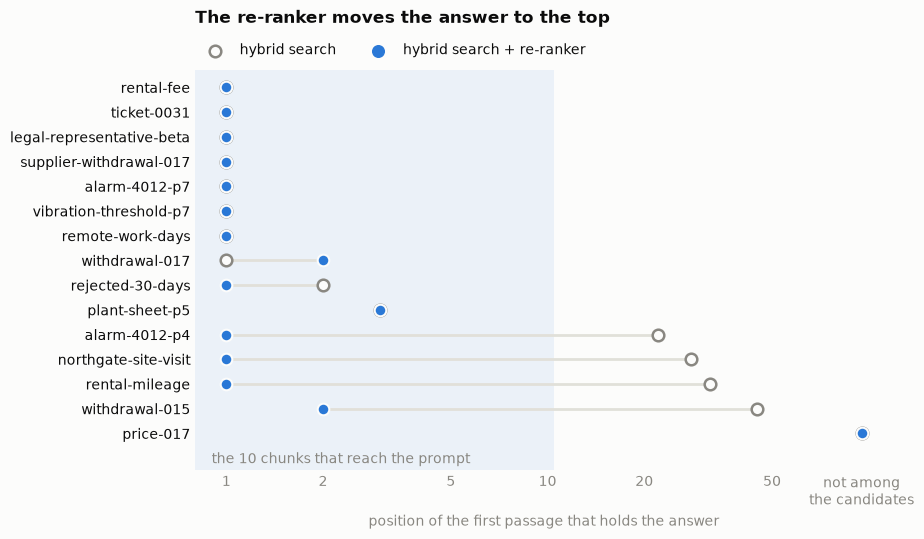

withdrawal-017           from 1 to 2
rejected-30-days         from 2 to 1
alarm-4012-p4            from 22 to 1
northgate-site-visit     from 28 to 1
rental-mileage           from 32 to 1
withdrawal-015           from 45 to 2


In [14]:
before = {name: position(hits, golden[name]) for name, hits in rankings["hybrid"].items()}
after = {name: position(hits, golden[name]) for name, hits in rankings["hybrid + re-ranker"].items()}
MISSING = CANDIDATES * 1.9  # where a passage that is not among the candidates is drawn
order = sorted(golden, key=lambda name: (before[name] or MISSING, after[name] or MISSING), reverse=True)

figure, axis = plt.subplots(figsize=(9, 5.2))
axis.axvspan(0.8, TOP_K + 0.5, color=BLUE, alpha=0.08, linewidth=0)
for row, name in enumerate(order):
    start, end = before[name] or MISSING, after[name] or MISSING
    axis.plot([start, end], [row, row], color=GRID, linewidth=2, zorder=1)
    axis.scatter(start, row, s=70, facecolor=SURFACE, edgecolor=MUTED, linewidth=1.8, zorder=2)
    axis.scatter(end, row, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
axis.scatter([], [], s=70, facecolor=SURFACE, edgecolor=MUTED, linewidth=1.8, label="hybrid search")
axis.scatter([], [], s=70, color=BLUE, label="hybrid search + re-ranker")
axis.set_xscale("log")
axis.set_xlim(0.8, MISSING * 1.25)
ticks = {1: "1", 2: "2", 5: "5", 10: "10", 20: "20", 50: "50", MISSING: "not among\nthe candidates"}
axis.set_xticks(list(ticks), list(ticks.values()))
axis.minorticks_off()
axis.set_yticks(range(len(order)), order)
axis.set_ylim(-1.5, len(order) - 0.3)
axis.set_xlabel("position of the first passage that holds the answer", color=MUTED)
axis.text(0.9, -1.05, f"the {TOP_K} chunks that reach the prompt", color=MUTED, va="center")
axis.tick_params(length=0, colors=INK)
axis.tick_params(axis="x", colors=MUTED)
axis.spines[:].set_visible(False)
axis.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.0), ncol=2, frameon=False)
axis.set_title("The re-ranker moves the answer to the top", loc="left", fontweight="bold", pad=34)
plt.show()

for name in reversed(order):
    if before[name] != after[name]:
        print(f"{name:24} from {before[name] or 'not found'} to {after[name] or 'not found'}")

Four questions had their answer between position 22 and position 45, where the language model
would never read it: after the re-ranker it is first or second for all four. Nothing that was at the
top was lost.

One question stays out, `price-017`: its passage is not among the 50 candidates, and the re-ranker
can only sort what the search gives it. That passage is an article of an addendum, *«Il
corrispettivo annuo per il servizio è pari a euro 192.000,00»*, and its text never says which
contract it belongs to: only the name of the file does.

Now the same rankings as numbers, on the ten chunks that reach the prompt. **Recall** is the share of
the golden passages that were found; **MRR** says how high the first one is (1 when it is always
first, 0.5 when it is always second).

In [15]:
def mean_scores(name: str) -> dict[str, float]:
    """Retrieval metrics of one setting, averaged over the questions."""
    rows = [retrieval_result(golden[key], hits[:TOP_K]) for key, hits in rankings[name].items()]
    return {
        "recall": float(np.mean([row.recall for row in rows])),
        "mrr": float(np.mean([row.reciprocal_rank for row in rows])),
        "ndcg": float(np.mean([row.ndcg for row in rows])),
    }


scores = {name: mean_scores(name) for name in SETTINGS}
print(f"{'':20} {'Recall':>8} {'MRR':>8} {'NDCG':>8}")
for name, row in scores.items():
    print(f"{name:20} {row['recall']:8.2f} {row['mrr']:8.2f} {row['ndcg']:8.2f}")

                       Recall      MRR     NDCG
dense                    0.70     0.56     0.55
sparse                   0.57     0.49     0.48
hybrid                   0.60     0.59     0.53
dense + re-ranker        0.92     0.89     0.86
hybrid + re-ranker       0.86     0.82     0.79


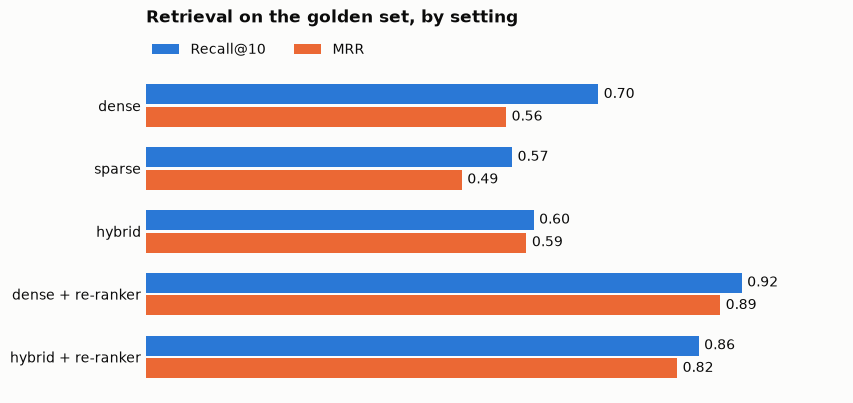

In [16]:
names = list(SETTINGS)
rows = np.arange(len(names))
figure, axis = plt.subplots(figsize=(9, 4.2))
series = (("recall", f"Recall@{TOP_K}", BLUE), ("mrr", "MRR", ORANGE))
for offset, (metric, label, color) in enumerate(series):
    values = [scores[name][metric] for name in names]
    bars = axis.barh(rows + (offset - 0.5) * 0.36, values, height=0.32, color=color, label=label)
    axis.bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=4, color=INK)
axis.set_yticks(rows, names)
axis.invert_yaxis()
axis.set_xlim(0, 1.08)
axis.set_xticks([])
axis.tick_params(length=0, colors=INK)
axis.spines[:].set_visible(False)
axis.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.0), ncol=2, frameon=False)
axis.set_title("Retrieval on the golden set, by setting", loc="left", fontweight="bold", pad=34)
plt.show()

Three things to read here.

- **The re-ranker is the step that changes the result.** Recall goes from 0.60-0.70 to 0.86-0.92
  and MRR from under 0.6 to over 0.8: the passage that answers is almost always first or second.
- **Hybrid search alone is not better than dense search on this corpus.** It ranks the first right
  passage slightly higher (MRR 0.59 against 0.56) and finds fewer of them (Recall 0.60 against
  0.70). These documents are contracts and manuals that repeat the same words, so a search by terms
  brings in many look-alikes, and the question in another language loses its passage.
- **With the re-ranker, dense and hybrid differ by one question**, `price-017` again: its passage
  is among the 50 candidates of the dense search and not among the 50 that survive the fusion.
  With 15 questions, one question is worth 0.07 of Recall: too little to name a winner.

## 6. What it costs

The search is a lookup in an index. The re-ranker runs a large model once for every candidate, on
every question.

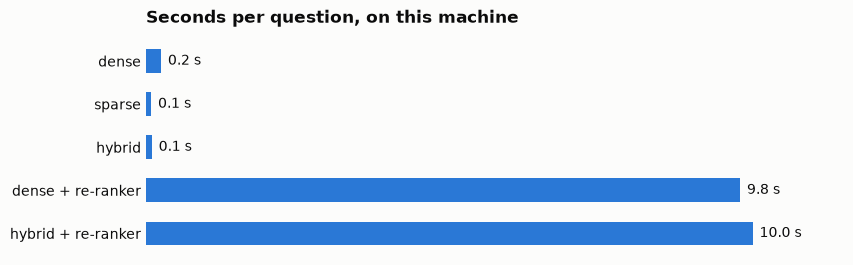

In [17]:
figure, axis = plt.subplots(figsize=(9, 2.8))
bars = axis.barh(names, [seconds[name] for name in names], color=BLUE, height=0.55)
axis.bar_label(bars, labels=[f"{seconds[name]:.1f} s" for name in names], padding=5, color=INK)
axis.invert_yaxis()
axis.set_xlim(0, max(seconds.values()) * 1.15)
axis.set_xticks([])
axis.tick_params(length=0, colors=INK)
axis.spines[:].set_visible(False)
axis.set_title("Seconds per question, on this machine", loc="left", fontweight="bold", pad=12)
plt.show()

The search answers in a fraction of a second; the re-ranker needs several seconds on a CPU, and
the time grows with the number of candidates. This is why it never reads the whole corpus: at this
speed, 1754 chunks would take minutes for a single question. Next to the language model, which
takes tens of seconds to write an answer, the wait is acceptable; on a GPU it is a fraction of it.

## What we keep

Step 4 builds the complete RAG on this pipeline, the one of the slides, and the web application
runs the same:

- `retrieval.mode: hybrid`: 50 candidates from each search, fused with RRF;
- `reranking.enabled: true`: `BAAI/bge-reranker-v2-m3` reads the 50 candidates and the best 10
  reach the prompt.

The measurements say where its value comes from: the re-ranker. Hybrid search neither helps nor
hurts in a way that 15 questions can prove; it is one question behind dense search. A larger golden
set, with more questions built around codes and exact names, would be needed to settle it. Until
then the choice is one line of `src/conf/config.yaml`: change `retrieval.mode`, run section 5 again
and decide on the numbers.

What no setting of this notebook fixes is a chunk whose text does not say what it is about, like
the article of the addendum above. The remedy belongs to chunking: put the name of the document in
the text that is embedded.